# 05 · Previsões com o modelo vigente e comparação de ciclos

- Carrega `models/modelo_vigente.json` e o modelo serializado, que já traz o pré-processamento e a lista de features.
- Gera previsões para o **conjunto de teste reservado**, que nunca foi usado para escolher modelos, features ou promoção.
- Compara os ciclos (histórico local e MLflow).

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import warnings
warnings.filterwarnings("ignore")
import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.utils import preparar_ambiente, carregar_config, carregar_contexto, salvar_contexto, dir_evidencias, configurar_mlflow
preparar_ambiente()
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
from src.ingestao import carregar_teste, carregar_treino_acumulado, carregar_validacao
from src.modelagem import baseline_mae, metricas
from src.particionamento import validar_separacao
from src.prever import carregar_modelo_vigente, prever
from src.promocao import carregar_manifesto, HISTORICO_CICLOS

ctx = carregar_contexto()
ev = dir_evidencias(ctx["cycle_id"])
manifesto = carregar_manifesto()
modelo = carregar_modelo_vigente()
teste = carregar_teste(cfg)
treino = carregar_treino_acumulado(cfg)
validar_separacao(treino=treino, validacao=carregar_validacao(cfg), teste=teste)
alvo = cfg["dados"]["alvo"]

pred = modelo.predict(teste.drop(columns=[alvo]))
met_teste = metricas(teste[alvo], pred)
met_teste["baseline_mae"] = baseline_mae(treino[alvo], teste[alvo])
print(f"Modelo vigente: {manifesto['algoritmo']} (promovido no ciclo {manifesto['cycle_id']}, dados {manifesto['data_version']})")
print("Features usadas:", manifesto["features"])
print(f"TESTE reservado ({len(teste)} amostras): MAE={met_teste['mae']:.3f} MPa | RMSE={met_teste['rmse']:.3f} | R²={met_teste['r2']:.3f}")

saida = teste.copy()
saida["previsao"] = pred
saida["erro_abs"] = (saida["previsao"] - saida[alvo]).abs()
saida.to_csv(ev / "previsoes_teste.csv", index=False)
display(saida.head(10))

Modelo vigente: random_forest (promovido no ciclo c20261124T230040Z-local, dados v4-16552413)
Features usadas: ['relacao_agua_aglomerante', 'log_idade', 'cimento', 'idade', 'aglomerante_total', 'relacao_agua_cimento']
TESTE reservado (204 amostras): MAE=4.188 MPa | RMSE=6.015 | R²=0.869


,cimento,escoria,cinza_volante,agua,superplastificante,agregado_graudo,agregado_miudo,idade,resistencia,previsao,erro_abs
0,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89,70.606436,8.716436
1,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27,41.955065,1.685065
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,42.357702,1.307702
3,304.0,76.0,0.0,228.0,0.0,932.0,670.0,28,47.81,31.596176,16.213824
4,304.0,76.0,0.0,228.0,0.0,932.0,670.0,365,55.26,53.813357,1.446643
5,332.5,142.5,0.0,228.0,0.0,932.0,594.0,90,37.72,41.269004,3.549004
6,332.5,142.5,0.0,228.0,0.0,932.0,594.0,180,39.78,41.686019,1.906019
7,304.0,76.0,0.0,228.0,0.0,932.0,670.0,90,49.19,50.431410,1.241410
8,304.0,76.0,0.0,228.0,0.0,932.0,670.0,180,50.95,51.816753,0.866753
9,332.5,142.5,0.0,228.0,0.0,932.0,594.0,28,33.02,36.645735,3.625735


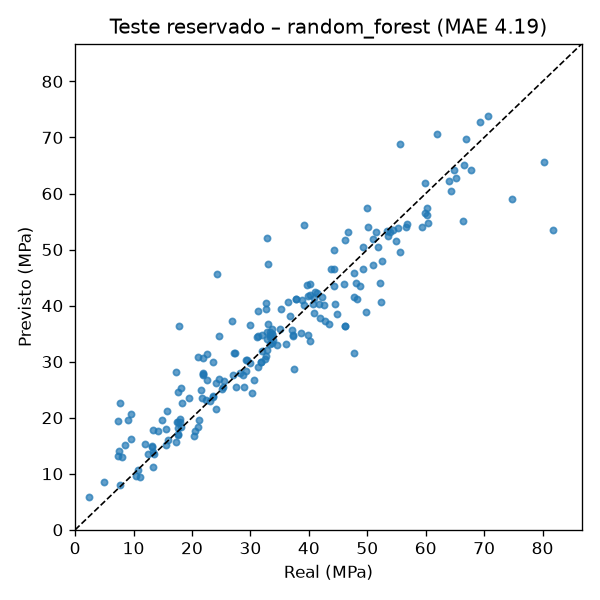

Previsão para nova mistura aos 28 dias: 41.96 MPa


In [3]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(teste[alvo], pred, s=14, alpha=0.7)
lim = [0, max(teste[alvo].max(), pred.max()) + 5]
ax.plot(lim, lim, "k--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Real (MPa)"); ax.set_ylabel("Previsto (MPa)")
ax.set_title(f"Teste reservado – {manifesto['algoritmo']} (MAE {met_teste['mae']:.2f})")
fig.tight_layout(); fig.savefig(ev / "previsto_vs_real.png", dpi=120); plt.close(fig)
display(Image(str(ev / "previsto_vs_real.png")))

# Exemplo de uso: previsão para uma nova mistura (traço típico, 28 dias)
print(f"Previsão para nova mistura aos 28 dias: {prever():.2f} MPa")

## Comparação entre ciclos

,cycle_id,gatilho,lote,data_version,n_treino,features_eleitas,mae_ridge,mae_random_forest,vencedor,mae_vigente_antes,decisao,vigente_apos,drift_alerta
0,c20261124T225840Z-local,local,lote_01.csv,v1-f78d2fdb,342,idade|aglomerante_total|log_idade|relacao_agua...,6.5611,6.2090,random_forest,NaN,promovido,random_forest@c20261124T225840Z-local,False
1,c20261124T225921Z-local,local,lote_02.csv,v2-075a21dd,442,aglomerante_total|log_idade|relacao_agua_cimen...,6.0461,5.7281,random_forest,6.2090,promovido,random_forest@c20261124T225921Z-local,False
2,c20261124T230002Z-local,local,lote_03.csv,v3-c6be3d56,542,relacao_agua_cimento|log_idade|relacao_agua_ag...,6.1568,5.7836,random_forest,5.7281,mantido,random_forest@c20261124T225921Z-local,False
3,c20261124T230040Z-local,local,lote_04.csv,v4-16552413,670,relacao_agua_aglomerante|log_idade|cimento|ida...,6.1573,4.8161,random_forest,5.7281,promovido,random_forest@c20261124T230040Z-local,True


Histórico recuperado do MLflow (runs de treino):


,cycle_id,data_version,algoritmo,val_mae,cv_mae,resultado
0,c20261124T225840Z-local,v1-f78d2fdb,ridge,6.561130,5.711057,perdeu
1,c20261124T225840Z-local,v1-f78d2fdb,random_forest,6.208989,4.732138,promovido
2,c20261124T225921Z-local,v2-075a21dd,ridge,6.046074,5.611133,perdeu
3,c20261124T225921Z-local,v2-075a21dd,random_forest,5.728106,4.814142,promovido
4,c20261124T230002Z-local,v3-c6be3d56,ridge,6.156789,5.578594,perdeu
5,c20261124T230002Z-local,v3-c6be3d56,random_forest,5.783596,4.671044,venceu_mas_nao_promovido
6,c20261124T230040Z-local,v4-16552413,ridge,6.157271,5.721437,perdeu
7,c20261124T230040Z-local,v4-16552413,random_forest,4.816130,4.558133,promovido


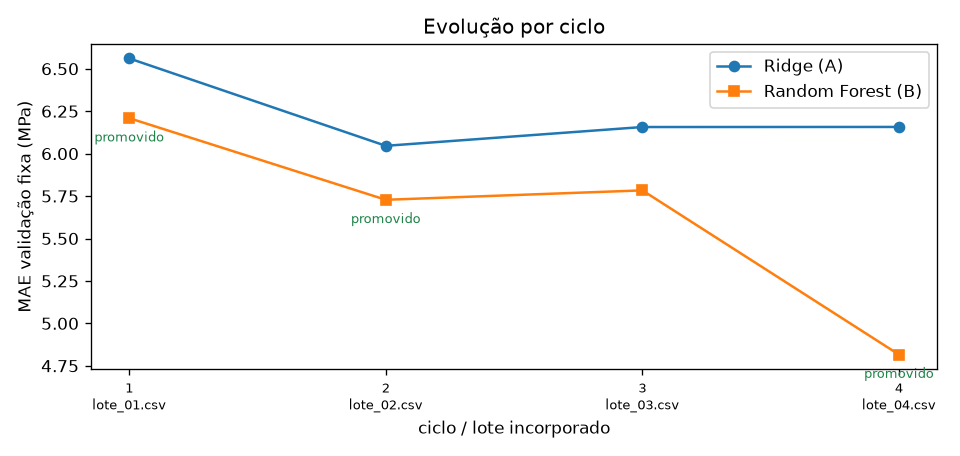

{'cycle_id': 'c20261124T230040Z-local',
 'data_version': 'v4-16552413',
 'lote': 'lote_04.csv',
 'n_treino': 670,
 'gatilho': 'local',
 'etl': {'linhas_recebidas': 128,
  'removidas_alvo_ausente': 0,
  'removidas_traco_incompleto': 0,
  'removidas_fora_da_faixa': 0,
  'removidas_duplicadas_no_lote': 0,
  'removidas_ja_incorporadas': 0,
  'ausentes_para_imputacao': 0,
  'linhas_aceitas': 128},
 'drift_resumo': '7/9 variáveis com drift (KS, p<0.05) – ALERTA',
 'drift_alerta': True,
 'run_etl': '552c025405404b019ac98f090f4c9f5d',
 'features_eleitas': ['relacao_agua_aglomerante',
  'log_idade',
  'cimento',
  'idade',
  'aglomerante_total',
  'relacao_agua_cimento'],
 'criterio_votacao': '>= 2 votos',
 'selecao_por_metodo': {'selectkbest_f_regression': ['aglomerante_total',
   'cimento',
   'log_idade',
   'relacao_agua_aglomerante',
   'relacao_agua_cimento'],
  'importancia_random_forest': ['aglomerante_total',
   'idade',
   'log_idade',
   'relacao_agua_aglomerante',
   'relacao_agua_c

In [4]:
hist = pd.read_csv(HISTORICO_CICLOS)
display(hist)

mlflow = configurar_mlflow(cfg)
runs = mlflow.search_runs(filter_string="tags.etapa = 'treino'", order_by=["start_time ASC"])
tab = runs[["tags.cycle_id", "tags.data_version", "tags.algoritmo", "metrics.val_mae", "metrics.cv_mae_media", "tags.resultado"]]
tab.columns = ["cycle_id", "data_version", "algoritmo", "val_mae", "cv_mae", "resultado"]
print("Histórico recuperado do MLflow (runs de treino):")
display(tab)

if len(hist) >= 1:
    fig, ax = plt.subplots(figsize=(8, 3.8))
    x = range(len(hist))
    ax.plot(x, hist["mae_ridge"], "o-", label="Ridge (A)")
    ax.plot(x, hist["mae_random_forest"], "s-", label="Random Forest (B)")
    for i, d in enumerate(hist["decisao"]):
        if d == "promovido":
            ax.annotate("promovido", (i, min(hist.loc[i, "mae_ridge"], hist.loc[i, "mae_random_forest"])),
                        textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="#1e8449")
    ax.set_xticks(list(x)); ax.set_xticklabels([f"{c}\n{l}" for c, l in zip(range(1, len(hist) + 1), hist["lote"])], fontsize=8)
    ax.set_ylabel("MAE validação fixa (MPa)"); ax.set_xlabel("ciclo / lote incorporado"); ax.legend(); ax.set_title("Evolução por ciclo")
    fig.tight_layout(); fig.savefig(RAIZ / "evidencias" / "evolucao_ciclos.png", dpi=120); plt.close(fig)
    display(Image(str(RAIZ / "evidencias" / "evolucao_ciclos.png")))

with mlflow.start_run(run_name=f"previsoes_{ctx['cycle_id']}"):
    mlflow.set_tags({"cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"], "etapa": "previsoes",
                     "modelo_vigente": f"{manifesto['algoritmo']}@{manifesto['cycle_id']}"})
    mlflow.log_metrics({f"teste_{k}": v for k, v in met_teste.items()})
    mlflow.log_artifact(str(ev / "previsoes_teste.csv"), "previsoes")
salvar_contexto({"teste": met_teste})